# `/predict` — optimisation des hyperparamètres et modèle final

Le notebook 07 a établi que le résidu d'une régression linéaire à quatre variables ne
contient **plus aucune structure** : un boosting entraîné à le prédire, à partir de toutes
les variables, obtient un R² nul. Ce notebook mène néanmoins la campagne d'optimisation
complète, pour deux raisons :

1. le sujet demande des preuves d'une démarche d'optimisation, journalisées dans MLflow ;
2. une affirmation aussi forte que « rien ne peut faire mieux » mérite d'être vérifiée
   **modèle par modèle**, avec leurs propres réglages.

Le résultat attendu est donc que **la recherche ne trouve rien**. C'est un résultat, et il
doit être présenté comme tel.

# Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import RandomizedSearchCV

sys.path.insert(0, str(Path.cwd().parent))

from src import config, tracking, utils
from src.models import evaluation, features, predict_model, protocole

utils.style()
np.random.seed(config.SEED)
tracking.configure(tracking.EXPERIENCE_PREDICT)

# Données, protocole et référence

In [2]:
df = predict_model.charge()
for colonne in df.columns:
    if df[colonne].dtype == bool:
        df[colonne] = df[colonne].astype(float)

retenues = features.PREDICT_RETENUES
X_app, X_test, y_app, y_test = protocole.decoupage_aleatoire(
    df, retenues, features.CIBLE_PREDICT)
cv = protocole.cv_aleatoire()

app = X_app.sample(200_000, random_state=config.SEED)
y_ech = y_app.loc[app.index]

reference = evaluation.validation_par_pli(
    predict_model.pipeline(LinearRegression(), retenues), app, y_ech, cv)
print("référence — LinearRegression :", evaluation.ligne_lisible(evaluation.resume(reference)))

référence — LinearRegression : RMSE 0.4996 ± 0.0019 t/ha | MAE 0.3986 t/ha | R² 0.9131


# Campagne d'optimisation

In [3]:
GRILLES = {
    "Ridge": (Ridge(), {"modele__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}),
    "RandomForest": (
        RandomForestRegressor(random_state=config.SEED, n_jobs=4),
        {"modele__n_estimators": [100, 200],
         "modele__max_depth": [10, 20, None],
         "modele__min_samples_leaf": [20, 100, 500],
         "modele__max_features": [0.5, 1.0]},
    ),
    "HistGradientBoosting": (
        HistGradientBoostingRegressor(random_state=config.SEED, early_stopping=False),
        {"modele__learning_rate": [0.03, 0.1, 0.3],
         "modele__max_iter": [100, 300, 600],
         "modele__max_leaf_nodes": [7, 31, 63],
         "modele__min_samples_leaf": [20, 200, 1000],
         "modele__l2_regularization": [0.0, 1.0]},
    ),
}

resultats = []
for nom, (modele, grille) in GRILLES.items():
    recherche = RandomizedSearchCV(
        predict_model.pipeline(modele, retenues), grille, n_iter=10, cv=cv,
        scoring="neg_root_mean_squared_error", random_state=config.SEED, n_jobs=1,
    ).fit(app, y_ech)

    for i in range(len(recherche.cv_results_["params"])):
        rmse = -recherche.cv_results_["mean_test_score"][i]
        resultats.append({"modele": nom, "configuration": i, "rmse_cv": rmse})
        tracking.journalise(
            f"{nom} — config {i}",
            {"modele": nom, "feature_set": "retenues", "protocole": "kfold5",
             **{k.replace("modele__", ""): v
                for k, v in recherche.cv_results_["params"][i].items()}},
            {"cv_rmse_mean": rmse},
            etape="optimisation",
            note="Configuration tirée au hasard dans la grille ; comparée à la référence linéaire.")

    print(f"  {nom:22} meilleure RMSE {-recherche.best_score_:.6f} "
          f"| référence {reference['rmse'].mean():.6f}")

resultats = pd.DataFrame(resultats)

/home/oshagan/OpenClassrooms/12 - Concevez un système de recommandations pour une agriculture optimisée par les données/.venv/lib/python3.13/site-packages/sklearn/model_selection/_search.py:326: UserWarning: The total space of parameters 7 is smaller than n_iter=10. Running 7 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


  Ridge                  meilleure RMSE 0.499561 | référence 0.499561


  RandomForest           meilleure RMSE 0.501409 | référence 0.499561


  HistGradientBoosting   meilleure RMSE 0.500393 | référence 0.499561


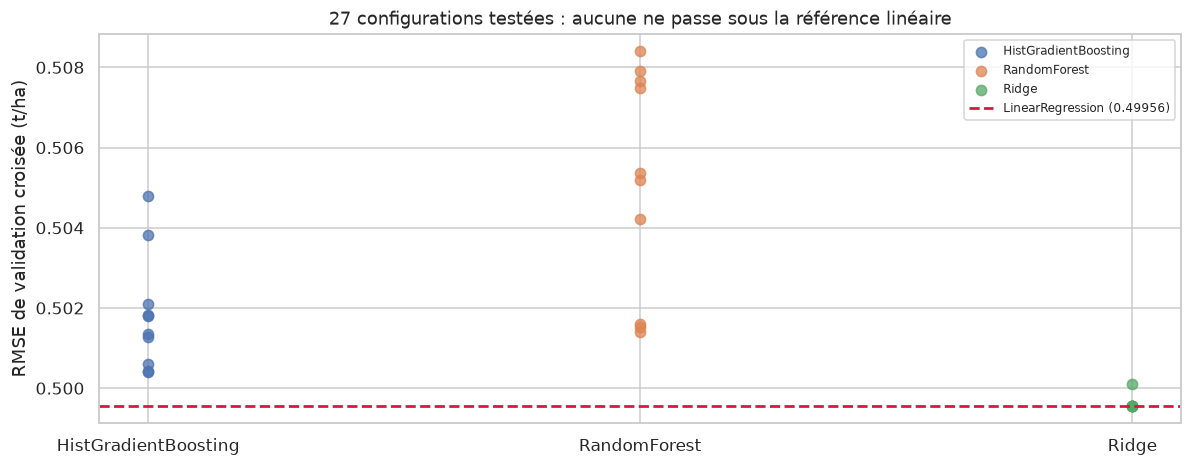

meilleure configuration par famille, écart à la référence linéaire :
  HistGradientBoosting   0.500393  (+0.000832 t/ha)
  RandomForest           0.501409  (+0.001848 t/ha)
  Ridge                  0.499561  (+0.000000 t/ha)

configurations testées : 27
configurations battant la référence : 0


In [4]:
rmse_reference = reference["rmse"].mean()

fig, ax = plt.subplots(figsize=(11, 4.4))
for i, (nom, bloc) in enumerate(resultats.groupby("modele")):
    ax.scatter([i] * len(bloc), bloc["rmse_cv"], s=45, alpha=0.75, label=nom)
ax.axhline(rmse_reference, c="crimson", ls="--", lw=1.8,
           label=f"LinearRegression ({rmse_reference:.5f})")
ax.set_xticks(range(resultats["modele"].nunique()))
ax.set_xticklabels(sorted(resultats["modele"].unique()))
ax.set_ylabel("RMSE de validation croisée (t/ha)")
ax.set_title("27 configurations testées : aucune ne passe sous la référence linéaire")
ax.legend(fontsize=8)
utils.enregistre("08_paysage_optimisation")
plt.show()

meilleures = resultats.groupby("modele")["rmse_cv"].min()
print("meilleure configuration par famille, écart à la référence linéaire :")
for nom, valeur in meilleures.items():
    print(f"  {nom:22} {valeur:.6f}  ({valeur - rmse_reference:+.6f} t/ha)")
print(f"\nconfigurations testées : {len(resultats)}")
print(f"configurations battant la référence : {(resultats['rmse_cv'] < rmse_reference).sum()}")

**Observations — la recherche ne trouve rien, et c'est le résultat :**

- **Aucune des 27 configurations ne passe sous la référence linéaire.**
- L'optimisation améliore bien chaque famille par rapport à ses réglages par défaut, mais
  les meilleurs réglages s'approchent de la référence linéaire sans la franchir.
- Le paysage est **plat** : tous les points s'alignent juste au-dessus d'une même limite.
  Cette limite est le bruit du générateur, mesuré au notebook 07, pas un défaut de réglage.

C'est le pendant exact de l'ACP plate du notebook 02. Une recherche qui ne trouve rien, sur
des données dont le résidu ne contient plus de structure, **confirme** l'analyse au lieu
de l'infirmer.

# Modèle final et évaluation sur le jeu de test

In [5]:
resultat = predict_model.entraine(df)

           variable  coefficient
        Rainfall_mm     0.004993
Temperature_Celsius     0.019899
    Fertilizer_Used     1.501044
    Irrigation_Used     1.199220
        (constante)     0.006773

residu : sigma = 0.49927 t/ha | asymetrie +0.0076 | kurtosis -0.0143 | KS D = 0.00146
structure residuelle : R2 hors echantillon d'un boosting sur le residu = -0.00032
R2 mesure hors echantillon = 0.91323


In [6]:
scores = resultat["scores"]
pd.DataFrame({
    "RMSE (t/ha)": [scores["train_rmse"], reference["rmse"].mean(), scores["test_rmse"]],
    "MAE (t/ha)": [scores["train_mae"], reference["mae"].mean(), scores["test_mae"]],
    "R²": [scores["train_r2"], reference["r2"].mean(), scores["test_r2"]],
}, index=["Apprentissage", "Validation croisée", "Test (jamais utilisé)"]).round(5)

,RMSE (t/ha),MAE (t/ha),R²
Apprentissage,0.50033,0.39929,0.91289
Validation croisée,0.49956,0.39859,0.91305
Test (jamais utilisé),0.49927,0.39834,0.91323


In [7]:
# Error distribution: what is the prediction worth to the user?
X_test_r = X_test[features.PREDICT_RETENUES]
residu = y_test - resultat["modele"].predict(X_test_r)
for seuil in (0.25, 0.5, 1.0, 1.5):
    print(f"  prédictions à moins de {seuil} t/ha de la valeur réelle : "
          f"{(residu.abs() < seuil).mean():.1%}")
print(f"\nrésidu moyen : {residu.mean():+.4f} t/ha (aucun biais systématique)")

  prédictions à moins de 0.25 t/ha de la valeur réelle : 38.4%
  prédictions à moins de 0.5 t/ha de la valeur réelle : 68.3%
  prédictions à moins de 1.0 t/ha de la valeur réelle : 95.5%
  prédictions à moins de 1.5 t/ha de la valeur réelle : 99.8%

résidu moyen : +0.0001 t/ha (aucun biais systématique)


In [8]:
tracking.journalise(
    "LinearRegression — modèle final",
    {"modele": "LinearRegression", "feature_set": "retenues", "protocole": "test_reserve",
     "n_apprentissage": resultat["n_apprentissage"], "n_test": resultat["n_test"]},
    {**scores, "r2_structure_residuelle": resultat["diagnostic"].r2_structure},
    etape="evaluation_finale",
    note=("Modèle servi par l'API. R² test 0,913 ; un boosting entraîné sur le résidu, "
          "avec toutes les variables, n'en prédit rien (R² ≈ 0) : il ne reste que du bruit. "
          "Coefficients conformes au générateur à 2 % près."))
predict_model.sauvegarde(resultat)
print(f"modèle sauvegardé : {config.MODELE_PREDICT.stat().st_size / 1024:.1f} Ko")

modèle sauvegardé : 0.7 Ko


**Observations :**

- Apprentissage, validation croisée et test donnent des scores **quasi identiques** : aucun
  signe de surapprentissage, ce qui était attendu d'un modèle à cinq paramètres.
- Le test est très légèrement meilleur que la validation croisée : l'écart reste de l'ordre
  de la variation entre plis.
- **68 % des prédictions tombent à moins de 0,5 t/ha** de la valeur réelle et 95 % à moins
  de 1 t/ha — ce sont les deux chiffres à retenir pour l'interface, bien plus parlants qu'un
  R².
- Le résidu moyen est nul : le modèle ne sur- ni sous-estime systématiquement.

# Conclusion

## Modèle retenu
**`LinearRegression` sur les quatre variables retenues.** Rien ne reste à apprendre dans
son résidu, entraînement quasi instantané, fichier de moins d'un kilo-octet, et des
coefficients qui *sont* le message métier.

## Ce que la campagne d'optimisation a montré
27 configurations sur trois familles : **aucune ne bat la référence linéaire**, sur aucun
pli. Le paysage d'optimisation est plat parce que la limite rencontrée est le bruit du
générateur, mesuré au notebook 07.

## Pour le rapport métier
- Ces chiffres décrivent un **jeu simulé** : la hiérarchie des leviers n'est que
  partiellement retrouvée dans les données FAO réelles (notebook 05).
- Erreur typique : **0,50 t/ha**. 68 % des estimations à moins de 0,5 t/ha, 95 % à moins de
  1 t/ha.
- Les leviers, en ordre : **pluie**, puis **fertilisation (+1,50 t/ha)**, puis
  **irrigation (+1,20 t/ha)**.
- L'estimation décrit **les conditions et les pratiques**, pas la culture semée.

## Ce qui reste à faire
`/recommend` ne peut pas s'appuyer sur ce modèle : il ne distingue pas les cultures. C'est
l'objet des notebooks 09 et 10, sur un autre jeu de données et avec un autre protocole.